In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from TrailPredictor.loading import load_activities

In [2]:
activities = load_activities()
print(activities.shape)
activities.head(3)

(1666, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
0,20698713759,"23 oct. 2026, 10:09:01",Entraînement aux poids le midi,weight_training,NaN,1596.0,0.00,157.0,5.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,142.0,NaN
1,20678393964,"21 oct. 2026, 16:43:26",[🏃‍♂️🏃‍♀️🏃🏼‍♀️ Blabla run avec katia et Marie 🌃],run,69 charge d'entraînement\n-- de COROS,5038.0,12.71,158.0,24.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
2,20673608797,"21 oct. 2026, 10:53:06",[🏋️ Pause renfo 💪],weight_training,NaN,2723.0,0.00,114.0,5.0,False,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,18.0,162.0,NaN


<Axes: xlabel='type', ylabel='count'>

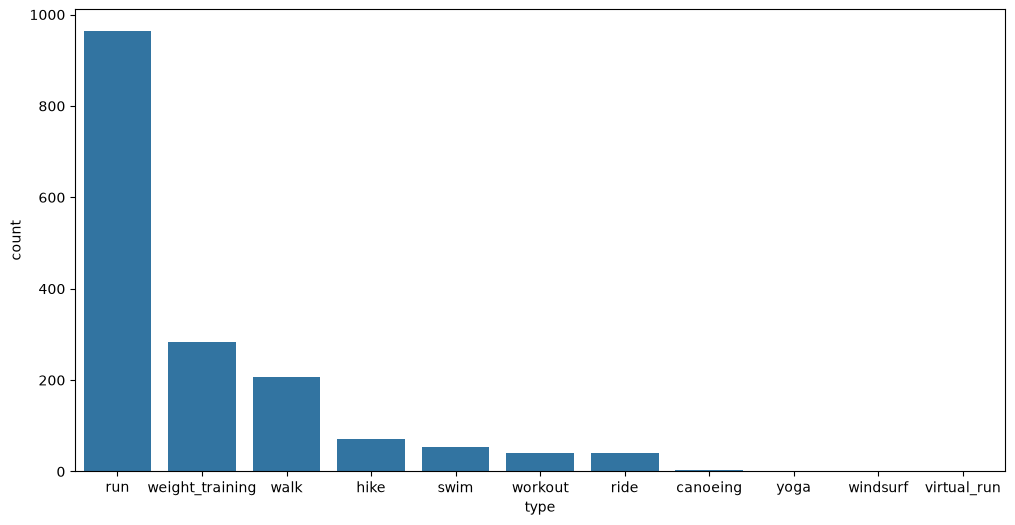

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=activities["type"].value_counts().reset_index(), x="type", y="count", ax=ax
)

In [4]:
act = activities[activities["type"] == "run"].sort_values(
    "distance_km", ascending=False
)
print(act.shape)
file_path = act[act["id"] == 11807872158].iloc[0]["file_name"]
act.head(5)

(963, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
683,13026008640,"30 nov. 2024, 23:11:13",[🏃 🏃🏼‍♀️ Saintélyon 🌜🌞],run,Une saintélyon en binôme avec [strava://athlet...,43813.0,82.36,179.0,577.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9564868f-742d-4b17-8c78-7fec7294c7bd.jpg...
908,10975302024,"16 mars 2024, 10:36:08",[🗼80k - Ecotrail de Paris 🎂],run,🎉Premier 80km pour mes 27ans 🎂 🎊\r\n\r\nPremie...,33706.0,81.87,187.0,1085.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f0e27ecf-caec-4e13-9ba7-d9357e9db464.jpg...
842,11682866712,"15 juin 2024, 07:30:40",[ 🐚 100k Saint-Jacques ],run,J'ai pris ma revanche sur le Saint-Jacques by ...,41920.0,81.01,183.0,1012.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9d9e4ea3-9dec-477f-a79e-568d549b0aa8.jpg...
193,17807912509,"21 mars 2026, 09:42:34",[🗼80k - Ecotrail de Paris 🎂],run,J'ai réussi à obtenir un dossard il y a une se...,38540.0,80.68,179.0,790.0,False,...,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,media/70e2f4f3-1a41-4374-a31f-33b248575d8b.jpg...
831,11807872158,"4 juil. 2024, 05:30:04",[ 🇪🇸 PDA - Val D'Aran byUTMB 🗻 ],run,Très content d'avoir pu m'aligner sur la ligne...,32759.0,51.39,188.0,868.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f2d3536c-3f32-4fdd-af8a-9bb4f5abcf66.jpg...


In [5]:
from TrailPredictor import RunningActivities

segment_width = 100
race = RunningActivities.from_computed_file(file_path, segment_width)
race.data.head(4)

/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,segment,elapsed_time,timestamp,distance,heart_rate,altitude,position_lat,position_long,speed,pace,accel_speed,accel_pace,log_speed,log_pace,log_accel_speed,log_accel_pace
0,0,0 days 00:00:40,2024-07-04 05:30:04+00:00,100.0,101.675000,1258.750000,42.707340,0.902902,2.500000,6.666667,0.000000,0.000000,0.916291,1.897120,-inf,-inf
1,1,0 days 00:00:33,2024-07-04 05:30:44+00:00,200.0,143.545455,1259.030303,42.707107,0.901687,3.030303,5.500000,0.530303,0.962500,1.108663,1.704748,-0.634307,-0.038221
2,2,0 days 00:00:30,2024-07-04 05:31:17+00:00,300.0,156.800000,1252.466667,42.707086,0.900635,3.333333,5.000000,0.303030,0.454545,1.203973,1.609438,-1.193922,-0.788457
3,3,0 days 00:00:34,2024-07-04 05:31:47+00:00,400.0,152.911765,1248.588235,42.706651,0.900157,2.941176,5.666667,-0.392157,-0.755556,1.078810,1.734601,NaN,NaN


In [6]:
from TrailPredictor.load_fit import load_fit_file
from pathlib import Path

content, _ = load_fit_file(Path("data") / "end_activity.fit")

pd.DataFrame(content["record"]).iloc[0, :].T

position_lat                       547279785.0
position_long                       74019999.0
enhanced_altitude                        769.6
enhanced_speed                           0.104
speed                                    0.104
gps_accuracy                               3.0
timestamp            2026-11-12 12:36:22+00:00
distance                                   NaN
Name: 0, dtype: object

In [17]:
race = RunningActivities.from_fit_file("end_activity.fit", segment_width=10)
race.data.head(15)

/home/caill/project/strava/TrailPredictor/activities.py:81: UserWarning: altitude column not found, using enhanced_altitude
  warn("altitude column not found, using enhanced_altitude")
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,segment,elapsed_time,timestamp,distance,heart_rate,altitude,position_lat,position_long,speed,pace,accel_speed,accel_pace,log_speed,log_pace,log_accel_speed,log_accel_pace
0,0,0 days 00:00:38,2026-11-12 12:36:22+00:00,10.0,NaN,770.374026,45.872478,6.204322,0.263158,63.333333,0.000000,0.000000,-1.335001,4.148412,-inf,-inf
1,1,0 days 00:00:08,2026-11-12 12:37:00+00:00,20.0,NaN,774.500000,45.872582,6.204362,1.250000,13.333333,0.986842,10.526316,0.223144,2.590267,-0.013245,2.353878
2,2,0 days 00:00:06,2026-11-12 12:37:08+00:00,30.0,NaN,776.250000,45.872661,6.204308,1.666667,10.000000,0.416667,2.500000,0.510826,2.302585,-0.875469,0.916291
3,3,0 days 00:00:08,2026-11-12 12:37:14+00:00,40.0,NaN,778.287500,45.872757,6.204299,1.250000,13.333333,-0.416667,-4.444444,0.223144,2.590267,NaN,NaN
4,4,0 days 00:00:05,2026-11-12 12:37:22+00:00,50.0,NaN,780.300000,45.872843,6.204318,2.000000,8.333333,0.750000,3.125000,0.693147,2.120264,-0.287682,1.139434
5,5,0 days 00:00:29,2026-11-12 12:37:27+00:00,60.0,NaN,783.037931,45.872894,6.204325,0.344828,48.333333,-1.655172,-232.000000,-1.064711,3.878121,NaN,NaN
6,6,0 days 00:00:09,2026-11-12 12:37:56+00:00,70.0,NaN,787.000000,45.873008,6.204311,1.111111,15.000000,0.766284,10.344828,0.105361,2.708050,-0.266203,2.336487
7,7,0 days 00:00:08,2026-11-12 12:38:05+00:00,80.0,NaN,790.625000,45.873091,6.204313,1.250000,13.333333,0.138889,1.481481,0.223144,2.590267,-1.974081,0.393043
8,8,0 days 00:00:09,2026-11-12 12:38:13+00:00,90.0,NaN,793.466667,45.873196,6.204338,1.111111,15.000000,-0.138889,-1.875000,0.105361,2.708050,NaN,NaN
9,9,0 days 00:00:09,2026-11-12 12:38:22+00:00,100.0,NaN,796.522222,45.873288,6.204354,1.111111,15.000000,0.000000,0.000000,0.105361,2.708050,-inf,-inf


In [21]:
race = RunningActivities.from_fit_file("activite_reconstituee.fit", segment_width=1)

/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [22]:
# race.plot.pace_by_segment().show()
# race.plot.hr_overlay().show()
race.plot.track_map().show()
# race.plot.altitude().show()
# race.plot.speed().show()
# race.plot.time_in_hr_zones()

In [ ]:
from TrailPredictor.plot import plot_minetti_curve

plot_minetti_curve()

In [ ]:
from TrailPredictor.dataset import Dataset

dataset_pred = Dataset()
dataset = Dataset.load(min_distance=40, max_distance=100, segment_width=500)
plotter = dataset.plot

/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/caill/project/strava/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [20]:
# plotter.merge_figure(plotter.target_histogram, title="Histogram of target ")
# plotter.merge_figure(
#     plotter.target_vs_feat, title="Target vs Altitude Drop", features="altitude_drop"
# ).show()
# plotter.merge_figure(
#     plotter.target_vs_feat,
#     title="Target vs Altitude Drop (Positive)",
#     features="altitude_drop_pos",
# )

In [ ]:
# dataset.features = [
#     "altitude_drop_pos",
#     "altitude_drop_neg_done",
#     "altitude_drop_pos_done",
#     "altitude_drop_pos_total",
#     "altitude_drop_pos_back_3km",
#     "altitude_drop_neg_back_10km",
#     # "running_cost",
#     # "walking_cost",
#     # "slope",
# ]

In [ ]:
from sklearn.model_selection import GroupKFold

dataset.target = "pace"
N_SPLITS = min(5, dataset.data["activity_id"].nunique())
RANDOM_STATE = 42
finite_rows = np.isfinite(dataset.target.to_numpy())
dataset._data = dataset._data.loc[finite_rows].reset_index(drop=True)
y = dataset.target
X = dataset.predictors
groups = dataset.data["activity_id"]

In [ ]:
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline

from regpath import (
    LassoPath,
    plot_lasso_path,
)

# create pipeline => preprocess + lasso + linear regression (on the features selected by lasso)
preprocess = dataset.get_preprocess()
cv = list(GroupKFold(n_splits=5).split(X, y, groups))
pipeline = Pipeline(
    [
        ("preprocess", preprocess),
        (
            "selection",
            SelectFromModel(LassoCV(cv=cv, random_state=RANDOM_STATE)),
        ),
        ("regression", LinearRegression()),
    ]
)
pipeline.fit(X, y)

/home/caill/project/strava/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.822630e+00, tolerance: 2.077e+00
  model = cd_fast.enet_coordinate_descent_gram(
/home/caill/project/strava/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.494461e+01, tolerance: 2.077e+00
  model = cd_fast.enet_coordinate_descent_gram(
/home/caill/project/strava/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the feature

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['distance','altitude','altitude_drop',...,'slope','walking_cost', 'running_cost']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

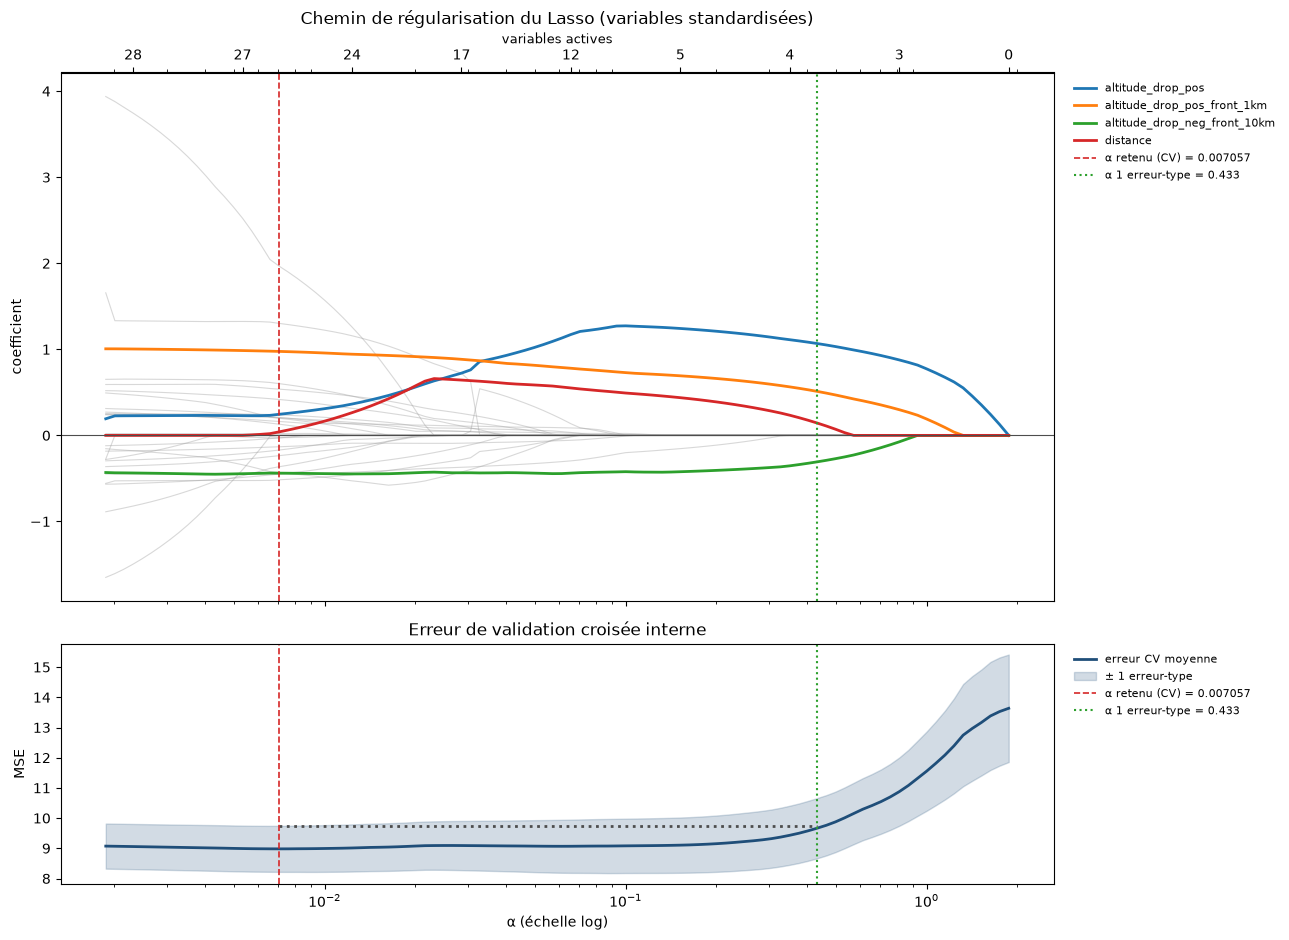

In [ ]:
res = LassoPath.from_pipeline(pipeline, X, y, lasso_step="selection")
fig, _ = plot_lasso_path(res)

,true_total_time,predict_total_time,error_total_time
activity_id,,,
0,0 days 12:10:13,0 days 11:23:02.609162176,0 days 00:47:10.390837824
1,0 days 09:21:47,0 days 10:22:21.861717978,0 days 01:00:34.861717978
2,0 days 11:38:40,0 days 12:01:43.889630564,0 days 00:23:03.889630564
3,0 days 10:42:20,0 days 10:17:31.248306792,0 days 00:24:48.751693208
4,0 days 09:05:59,0 days 08:59:25.494167325,0 days 00:06:33.505832675
5,0 days 05:17:46,0 days 05:05:32.858243926,0 days 00:12:13.141756074
6,0 days 06:38:38,0 days 05:26:14.201365396,0 days 01:12:23.798634604
7,0 days 05:52:52,0 days 06:29:20.885839204,0 days 00:36:28.885839204
8,0 days 05:55:50,0 days 05:05:49.510639401,0 days 00:50:00.489360599


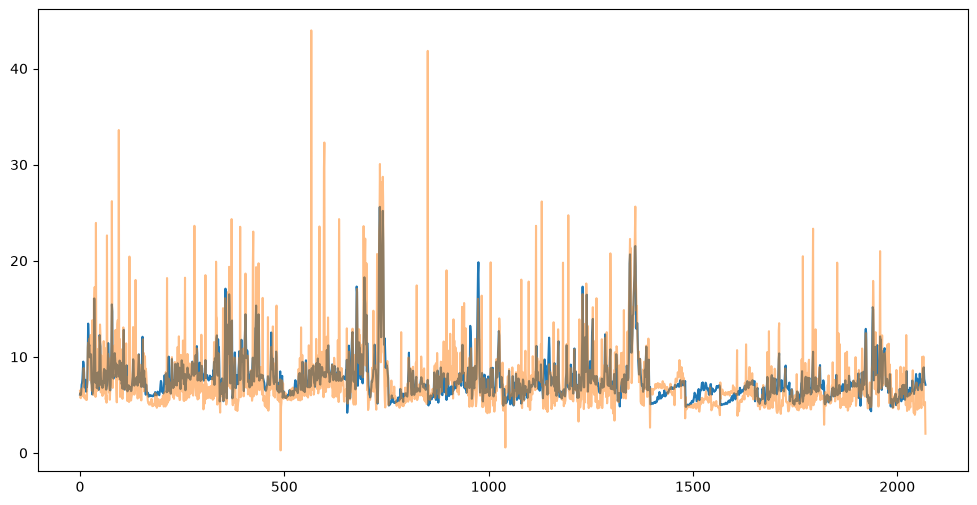

In [ ]:
from sklearn.model_selection import GroupKFold

# models = make_models()
# pred = cross_val_predict(models["linear"], X, y, groups=groups)
pred = pipeline.predict(X)

plt.figure(figsize=(12, 6))
plt.plot(pred)
plt.plot(dataset.target, alpha=0.5)

dataset.prediction = pred

results = pd.concat(
    [
        dataset.true_total_time,
        dataset.predict_total_time(),
        # dataset.error_total_time(),
    ],
    axis=1,
)

# absolute error in minutes
results["error_total_time"] = np.abs(
    results["predict_total_time"] - results["true_total_time"]
)
results

In [ ]:
race.data.columns

Index(['segment', 'elapsed_time', 'timestamp', 'distance', 'heart_rate',
       'altitude', 'position_lat', 'position_long', 'speed', 'pace',
       'accel_speed', 'accel_pace', 'log_speed', 'log_pace', 'log_accel_speed',
       'log_accel_pace'],
      dtype='str')

In [ ]:
race = dataset.get_activities(0)
race.plot.error_prediction().show()
race.plot.speed().show()

In [ ]:
for activity_id in dataset.data["activity_id"].unique()[:5]:
    # if (
    #     not "Mamores"
    #     in dataset._data[dataset._data["activity_id"] == activity_id]
    #     .loc[:, "name"]
    #     .values[0]
    # ):
    #     continue

    race = dataset.get_activities(activity_id)
    race.plot.speed().show()

In [ ]:
dataset.plot.vs_prediction()

/home/caill/project/strava/.venv/lib/python3.12/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


In [ ]:
# models = make_models()
# dataset.change_target("pace")
# finite_rows = np.isfinite(dataset.target.to_numpy())
# dataset._data = dataset._data.loc[finite_rows].reset_index(drop=True)
# y = dataset.target
# X = dataset.predictors
# groups = dataset.data["activity_id"]
# N_SPLITS = min(5, dataset.data["activity_id"].nunique())
# cv = GroupKFold(n_splits=N_SPLITS)
# rows = []
# for name, pipe in models.items():
#     pred = cross_val_predict(pipe, X, y, groups=groups, cv=cv)
#     dataset.prediction = pd.Series(pred, index=y.index, name="pace_pred")
#     err = dataset.true_total_time / dataset.predict_total_time() - 1
#     rows.append(
#         {
#             "modèle": name,
#             "R² vitesse": r2_score(y, pred),
#             "MAE": mean_absolute_error(y, pred),
#             "Predicted total time (%)": dataset.predict_total_time().mean(),
#             "Error total time (%)": err.abs().mean(),
#         }
#     )

# metrics = pd.DataFrame(rows).set_index("modèle")
# display_fn = globals().get("display", print)
# display_fn(metrics.round(3))

# best = metrics["MAE"].idxmin()
# print(f"Modèle retenu : {best}")